In [1]:
import numpy as np
import random
import math
import matplotlib.pyplot as plt

In [ ]:
#General rutine
def monte_carlo_integration(func, a, b, num_samples=1000):
    """
    Aproxima la integral definida de una función utilizando el método de Monte Carlo.

    Args:
        func: La función a integrar (debe ser una función de Python).
        a: El límite inferior de integración.
        b: El límite superior de integración.
        num_samples: El número de puntos aleatorios a generar.

    Returns:
        Una aproximación de la integral definida.
    """
    integral_sum = 0
    for _ in range(num_samples):
        # Generar un punto aleatorio en el intervalo [a, b]
        x = random.uniform(a, b)
        # Sumar el valor de la función en ese punto
        integral_sum += func(x)
    # Calcular el promedio y multiplicar por el ancho del intervalo
    integral_approx = (b - a) * (integral_sum / num_samples)
    return integral_approx

In [ ]:
import scipy.integrate as integrate

def f(x):
  return x**0.5

integrate.quad(f,0,4)

(5.333333333333335, 5.921189464667503e-15)

In [ ]:
a = 0
b = 4
num_samples = 100000
# Compute the integral using MonteCarlo
integral_result = monte_carlo_integration(f, a, b, num_samples)

print(f"MonteCarlo value: {integral_result}")
print(f"Analytical result : {16/3}")
print('error', abs(integral_result-16/3))

MonteCarlo value: 5.345072138344595
Analytical result : 5.333333333333333
error 0.011738805011262343


In [ ]:
f2 = lambda y, x: x*y**2
print(integrate.dblquad(f2, 0, 2, 0, 1))


(0.6666666666666667, 7.401486830834377e-15)


#El resultado de la doble integral $$ \int_{0}^{1} \int_{0}^{2} xy \, dx \, dy $$ es aproximdamente 0.66667

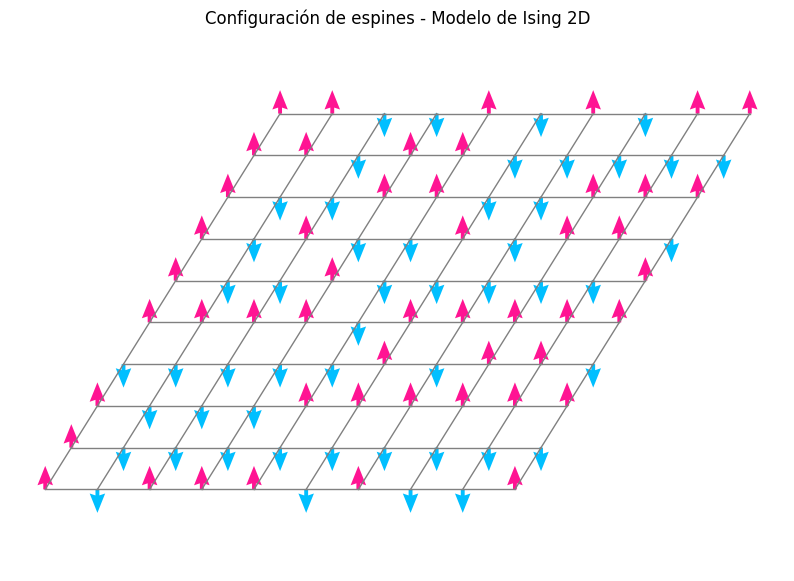

In [2]:
def graficar_espines(espines):

    N = len(espines)

    # Coordenadas de los sitios de la red
    x = []
    y = []

    for j in range(N):
        for i in range(N):

            x.append(i + 0.5*j)
            y.append(j*0.8)

    x = np.array(x)
    y = np.array(y)

    # Convertir la matriz en un vector
    s = espines.flatten()

    # Dibujar la red cristalina
    plt.figure(figsize=(10, 7))

    # Conexiones horizontales
    for j in range(N):
        for i in range(N-1):

            x1 = i + 0.5*j
            x2 = i + 1 + 0.5*j
            yy = j*0.8

            plt.plot([x1, x2], [yy, yy],
                     color='gray', linewidth=1)

    # Conexiones diagonales
    for j in range(N-1):
        for i in range(N):

            x1 = i + 0.5*j
            x2 = i + 0.5*(j+1)

            y1 = j*0.8
            y2 = (j+1)*0.8

            plt.plot([x1, x2], [y1, y2],
                     color='gray', linewidth=1)

    # Colores de los espines
    colores = []

    for spin in s:

        if spin == 1:
            colores.append('deeppink')
        else:
            colores.append('deepskyblue')

    # Dibujar las flechas
    plt.quiver(
        x, y,
        np.zeros(len(s)),
        s*0.45,
        color=colores,
        angles='xy',
        scale_units='xy',
        scale=1,
        width=0.005,
        headwidth=4,
        headlength=5
    )

    plt.title("Configuración de espines - Modelo de Ising 2D")
    plt.axis('equal')
    plt.axis('off')
    plt.show()


# Ejemplo
espines = np.random.choice([-1, 1], size=(10, 10))

graficar_espines(espines)

In [4]:
# Constante de interacción en Kelvin
J = 10.0

# Momento magnético de Bohr dividido por Boltzmann
mu_kB = 0.671714  # K/T


def metropolis(espines, T, H, J, n_equil, n_medicion):

    N = len(espines)

    magnetizacion = []

    # Número de pasos de Monte Carlo
    for paso in range(n_equil + n_medicion):

        # Intentar invertir N*N espines por paso
        for intento in range(N*N):

            # Seleccionar un sitio aleatorio
            i = np.random.randint(0, N)
            j = np.random.randint(0, N)

            # Orientación actual del espín
            s = espines[i, j]

            # Calcular los primeros vecinos
            vecinos = (
                espines[(i+1) % N, j] +
                espines[(i-1) % N, j] +
                espines[i, (j+1) % N] +
                espines[i, (j-1) % N]
            )

            # Cambio de energía al invertir el espín
            delta_E = 2*s*(J*vecinos + mu_kB*H)

            # Criterio de aceptación de Metropolis
            if delta_E <= 0:

                espines[i, j] = -s

            else:

                probabilidad = np.exp(-delta_E/T)

                numero_aleatorio = np.random.rand()

                if numero_aleatorio < probabilidad:

                    espines[i, j] = -s

        # Guardar la magnetización después del equilibrio
        if paso >= n_equil:

            m = np.mean(espines)

            magnetizacion.append(m)

    # Promedio de las mediciones
    magnetizacion_media = np.mean(magnetizacion)

    return magnetizacion_media

In [7]:
def metropolis_mc(L, T, H, mu=1.0, kb=1.0, steps=100_000):
    """
    Simulación de Monte Carlo para un sistema 2D de espines no interactuantes.
    L: Tamaño de la red (L x L)
    T: Temperatura
    H: Campo magnético
    """
    # 1. Configuración inicial aleatoria (+1 o -1)
    grid = np.random.choice([-1, 1], size=(L, L))
    N = L * L

    # Para estabilizar el sistema (termalización), descartamos los primeros pasos
    termalization_steps = int(0.1 * steps)

    magnetization_sum = 0
    samples = 0

    for step in range(steps):
        # 2. Visitar aleatoriamente un punto de la red
        i, j = np.random.randint(0, L, size=2)
        spin = grid[i, j]

        # 3. Comprobar energía (solo importa el término del campo externo al no haber interacción)
        dE = 2.0 * mu * H * spin # -> Este si es dE?

        # Aceptación de Metrópolis
        if dE < 0:
            grid[i, j] = -spin
        else:
            r = np.random.rand()
            if r < np.exp(-dE / (kb * T)):
                grid[i, j] = -spin

        # Tomar medidas después de la termalización para evitar el sesgo inicial
        if step > termalization_steps:
            magnetization_sum += np.sum(grid)
            samples += 1

    # Retorna la magnetización media por átomo y por unidad de tiempo
    return magnetization_sum / (samples * N)



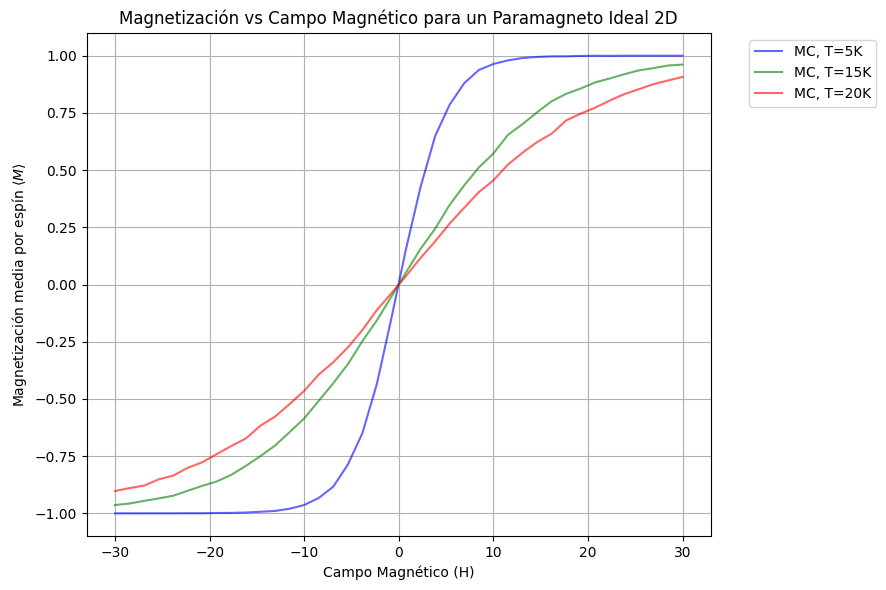

In [12]:
# Parámetros del ejercicio
L = 20  # Red de 20x20 = 400 átomos
T_values = [5, 15, 20]
H_values = np.linspace(-30, 30, 40)

# Diccionarios para almacenar resultados
M_mc = {T: [] for T in T_values}

for T in T_values:
    for H in H_values:
        # Resultado de Monte Carlo
        M_mc[T].append(metropolis_mc(L, T, H, steps=50000))
# Graficar
plt.figure(figsize=(9, 6))


for T in T_values:
    plt.plot(H_values, M_mc[T], '-', color=colors[T], label=f'MC, T={T}K', alpha=0.6)

plt.xlabel('Campo Magnético (H)')
plt.ylabel('Magnetización media por espín $\\langle M \\rangle$')
plt.title('Magnetización vs Campo Magnético para un Paramagneto Ideal 2D')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()